# Solución del Taller 2. Modulo Simulación de Procesos Industriales Curso de Ingeniería de Procesos


## Punto 1. Analisis estadístico de datos:

In [1]:
from google.colab import drive
drive.mount('/gdrive')

#Importamos la librerias necesarias para el manejo y analisis de los datos
import pandas as pd #Manejo de bases de datos
import numpy as np #Operaciones matriciales
import matplotlib.pyplot as plt #Graficador
from scipy import stats #Paquete estadistico

Mounted at /gdrive


In [2]:
df = pd.read_csv('/gdrive/MyDrive/Utadeo/Sesión 7/Observaciones_Turnos.csv',
sep = ';', decimal = '.', encoding = 'latin-1')
print(df.dtypes)

Turno                   object
H.Solicitud             object
H.Atención              object
H.Finalización          object
Sec                    float64
Rep                    float64
T.Espera                object
T.Llegada               object
T.Sala\n\r(Esp+Lle)     object
T.Atencion              object
T.Total                 object
Funcionario             object
Terminal                object
Area                    object
Tipo de cliente         object
Servicio                object
Subservicio             object
Calificación            object
Cod Cliente             object
Nombre                  object
Unnamed: 20            float64
dtype: object


In [3]:
#Hacemos la limpieza de filas vacías o nulas
df = df[df["H.Solicitud"].notna()].copy()
print(df['H.Solicitud'].describe())

count           17322
unique           7838
top       20/abr/2015
freq              448
Name: H.Solicitud, dtype: object


In [4]:
#Creamos columnaas con los datos de fecha y hora
df = df.copy()

df["Fecha"] = np.where(
    df.index % 2 == 0,
    df["H.Solicitud"],
    np.nan
)

df["Hora"] = np.where(
    df.index % 2 == 1,
    df["H.Solicitud"],
    np.nan
)
df["Fecha"] = df["Fecha"].ffill()
df["Hora"] = df["Hora"].bfill()
df[["Fecha","Hora"]].head()

,Fecha,Hora
0,01/abr/2015,07:01:04
1,01/abr/2015,07:01:04
2,01/abr/2015,07:01:11
3,01/abr/2015,07:01:11
4,01/abr/2015,07:01:19


In [5]:
#Traducimos los meses a inglés
meses_es_en = {
    "ene": "Jan",
    "feb": "Feb",
    "mar": "Mar",
    "abr": "Apr",
    "may": "May",
    "jun": "Jun",
    "jul": "Jul",
    "ago": "Aug",
    "sep": "Sep",
    "oct": "Oct",
    "nov": "Nov",
    "dic": "Dec"
}


df["Fecha"] = df["Fecha"].str.lower()

for es, en in meses_es_en.items():
    df["Fecha"] = df["Fecha"].str.replace(es, en, regex=False)


df[["Fecha","Hora"]].head()

,Fecha,Hora
0,01/Apr/2015,07:01:04
1,01/Apr/2015,07:01:04
2,01/Apr/2015,07:01:11
3,01/Apr/2015,07:01:11
4,01/Apr/2015,07:01:19


In [6]:
#Unimos la fecha y hora por llegada en una columna
df["Llegada"] = pd.to_datetime(
    df["Fecha"] + " " + df["Hora"],
    dayfirst=True,
    errors="coerce"
)
df_llegada = df[df.index % 2 == 0].copy()
df_llegada[["Llegada"]].head()

,Llegada
0,2015-04-01 07:01:04
2,2015-04-01 07:01:11
4,2015-04-01 07:01:19
6,2015-04-01 07:16:05
8,2015-04-01 07:17:01


In [7]:
#Ordenamos cronologicamente
df_llegada = df_llegada.sort_values("Llegada")

#Calculamos Interarrivals en minutos
df_llegada["Interarrival_min"] = (
    df_llegada["Llegada"].diff().dt.total_seconds() / 60
)
interarrivals = df_llegada["Interarrival_min"].dropna()
interarrivals.head(10)
interarrivals.describe()

,Interarrival_min
count,8660.000000
mean,4.897063
std,91.221688
min,0.000000
25%,0.400000
50%,0.950000
75%,2.183333
max,6545.100000


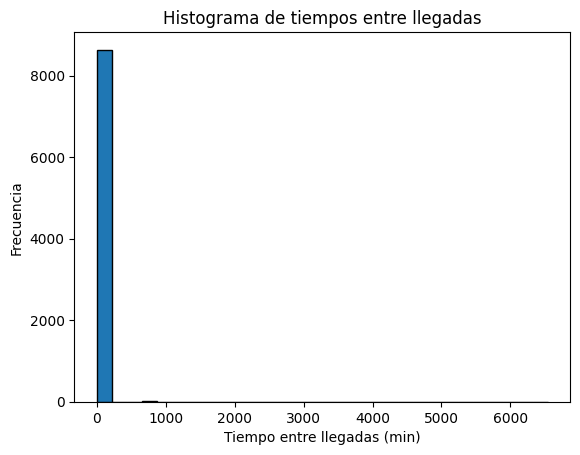

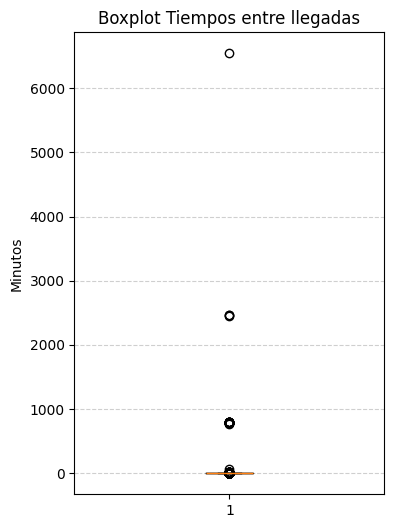

In [8]:
#Generamos hitograma y diagrama de cajas
plt.hist(interarrivals, bins=30,edgecolor='black')
plt.xlabel("Tiempo entre llegadas (min)")
plt.ylabel("Frecuencia")
plt.title("Histograma de tiempos entre llegadas")
plt.show()

plt.figure(figsize=(4,6))
plt.boxplot(interarrivals, vert=True, showfliers=True)
plt.title("Boxplot Tiempos entre llegadas")
plt.ylabel("Minutos")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()


count    8031.000000
mean        1.280550
std         1.136842
min         0.100000
25%         0.383333
50%         0.850000
75%         1.866667
max         4.850000
Name: Interarrival_min, dtype: float64


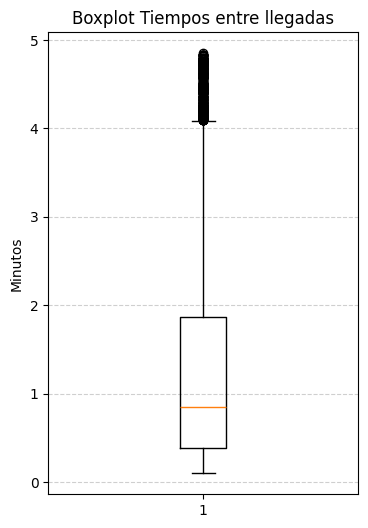

In [9]:
#Iniciamos la limpieza de los interarrivals
data = interarrivals.dropna()

Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

LI = Q1 - 1.5 * IQR
LS = Q3 + 1.5 * IQR
#Eliminamos los datos atipicos
data = data[
    (data >= 0.1) &
    (data <= LS)
]
print(data.describe())

#Generamos boxplot
plt.figure(figsize=(4,6))
plt.boxplot(data, vert=True, showfliers=True)
plt.title("Boxplot Tiempos entre llegadas")
plt.ylabel("Minutos")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

count    7765.000000
mean        1.172095
std         0.989841
min         0.100000
25%         0.383333
50%         0.816667
75%         1.733333
max         4.083333
Name: Interarrival_min, dtype: float64


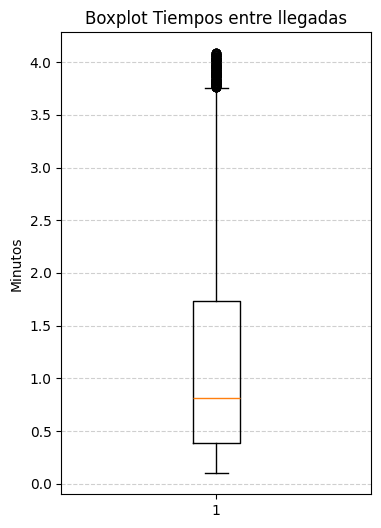

In [10]:
#Seguimos con la limpieza de los interarrivals
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

LI = Q1 - 1.5 * IQR
LS = Q3 + 1.5 * IQR
#Eliminamos los datos atipicos
data = data[
    (data >= 0.1) &
    (data <= LS)
]
print(data.describe())

#Generamos boxplot
plt.figure(figsize=(4,6))
plt.boxplot(data, vert=True, showfliers=True)
plt.title("Boxplot Tiempos entre llegadas")
plt.ylabel("Minutos")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

count    7626.000000
mean        1.121969
std         0.925795
min         0.100000
25%         0.366667
50%         0.791667
75%         1.650000
max         3.750000
Name: Interarrival_min, dtype: float64


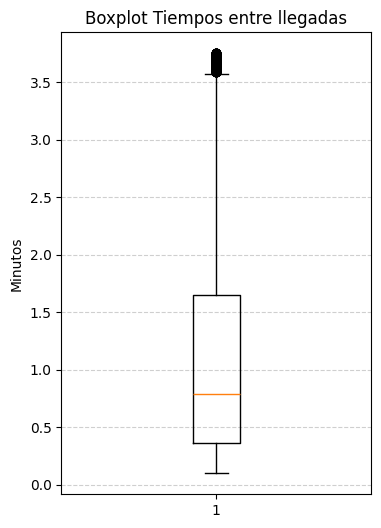

In [11]:
#Seguimos con la limpieza de los interarrivals
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

LI = Q1 - 1.5 * IQR
LS = Q3 + 1.5 * IQR
#Eliminamos los datos atipicos
data = data[
    (data >= 0.1) &
    (data <= LS)
]
print(data.describe())

#Generamos boxplot
plt.figure(figsize=(4,6))
plt.boxplot(data, vert=True, showfliers=True)
plt.title("Boxplot Tiempos entre llegadas")
plt.ylabel("Minutos")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

count    7519.000000
mean        1.085716
std         0.880669
min         0.100000
25%         0.366667
50%         0.783333
75%         1.616667
max         3.566667
Name: Interarrival_min, dtype: float64


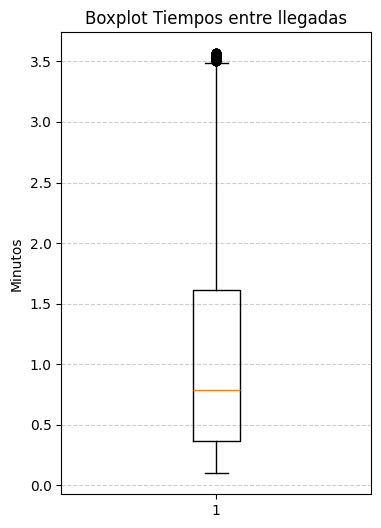

In [12]:
#Seguimos con la limpieza de los interarrivals
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

LI = Q1 - 1.5 * IQR
LS = Q3 + 1.5 * IQR
#Eliminamos los datos atipicos
data = data[
    (data >= 0.1) &
    (data <= LS)
]
print(data.describe())

#Generamos boxplot
plt.figure(figsize=(4,6))
plt.boxplot(data, vert=True, showfliers=True)
plt.title("Boxplot Tiempos entre llegadas")
plt.ylabel("Minutos")
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

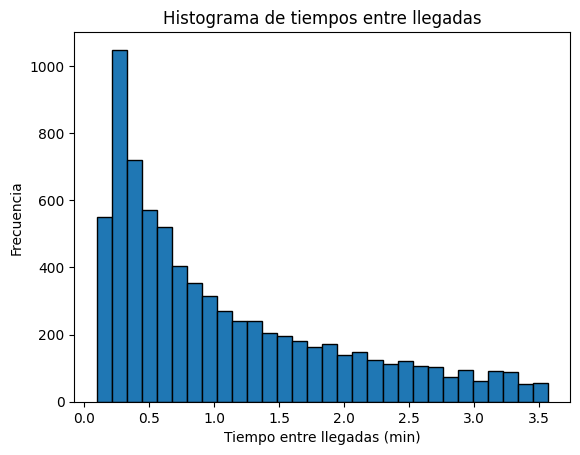

In [13]:
#Generamos histograma de los datos de llegada limpios
plt.hist(data, bins=30,edgecolor='black')
plt.xlabel("Tiempo entre llegadas (min)")
plt.ylabel("Frecuencia")
plt.title("Histograma de tiempos entre llegadas")
plt.show()

In [14]:
data.head(10)

,Interarrival_min
2,0.116667
4,0.133333
8,0.933333
12,0.233333
16,0.583333
18,1.183333
20,0.666667
24,1.266667
26,1.550000
28,1.850000


In [15]:
data.describe()

,Interarrival_min
count,7519.000000
mean,1.085716
std,0.880669
min,0.100000
25%,0.366667
50%,0.783333
75%,1.616667
max,3.566667


In [16]:
#Exportamos los datos limpios
data.to_csv("/gdrive/MyDrive/Utadeo/Sesión 8/Taller 2/Datos_limp_Taller2.csv", index=False,sep=";",decimal=",")

Parámetros para expon: (0.1, 0.9857161856629871)
Parámetros para gamma: (np.float64(1.104701694445914), np.float64(0.09941273817758242), np.float64(0.8928173994785087))
Parámetros para lognorm: (np.float64(0.991384207668985), 0.056466252106744635, np.float64(0.6733622956088215))


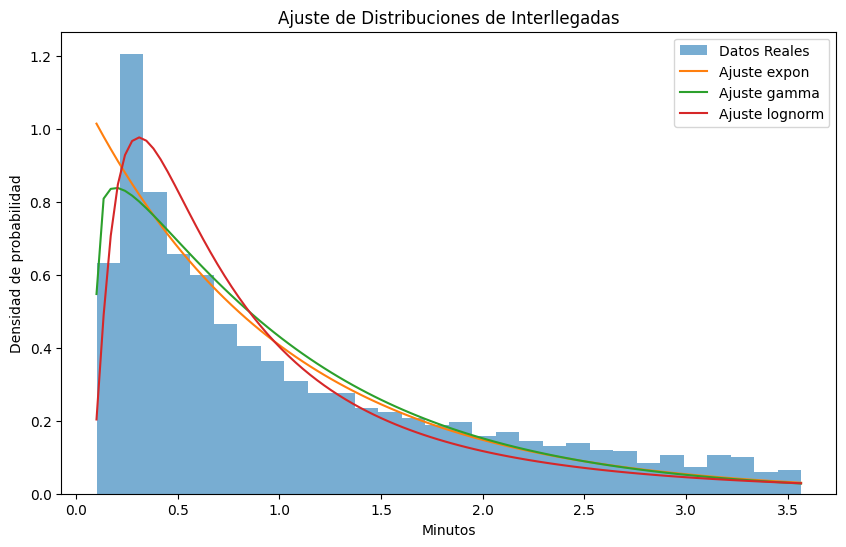

In [22]:
# 1. Definir las distribuciones a probar
# La Exponencial es la "reina" de las llegadas (Proceso de Poisson)
distribuciones = ['expon', 'gamma', 'lognorm']

# 2. Configurar el gráfico
plt.figure(figsize=(10, 6))
plt.hist(data, bins=30, density=True, alpha=0.6, label='Datos Reales')

# 3. Iterar y ajustar cada distribución
for dist_name in distribuciones:
    dist = getattr(stats, dist_name)
    # Ajustar la distribución a los datos
    params = dist.fit(data)

    # Generar valores para la línea del gráfico
    x = np.linspace(data.min(), data.max(), 100)
    pdf_fitted = dist.pdf(x, *params)

    plt.plot(x, pdf_fitted, label=f'Ajuste {dist_name}')
    print(f"Parámetros para {dist_name}: {params}")

plt.title('Ajuste de Distribuciones de Interllegadas')
plt.xlabel('Minutos')
plt.ylabel('Densidad de probabilidad')
plt.legend()
plt.show()

Prueba K-S para Log normal: Estadístico=0.0607, p-valor=0.0000
(np.float64(0.991384207668985), 0.056466252106744635, np.float64(0.6733622956088215))


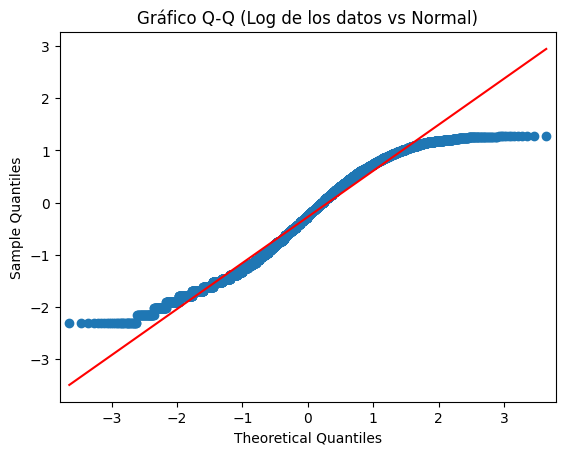

In [27]:
# Evaluación la distribución Log normal
params_lognorm = stats.lognorm.fit(data)
ks_stat, p_value = stats.kstest(data, 'lognorm', args=params_lognorm)

print(f"Prueba K-S para Log normal: Estadístico={ks_stat:.4f}, p-valor={p_value:.4f}")
print(params_lognorm)
import statsmodels.api as sm

# Graficar Q-Q plot para Lognormal
# Usamos el logaritmo de los datos porque el log de una Lognormal es una Normal
fig = sm.qqplot(np.log(data), line='s')
plt.title("Gráfico Q-Q (Log de los datos vs Normal)")
plt.show()

Parámetros optimizados (mínimos cuadrados): [1.38270791 0.1149382  0.68343582]
MSE (Menor es mejor): 0.002746
R-squared: 0.9596
Media Real: 1.0857 vs Media Modelo: 1.8747
Std Real: 0.8807 vs Std Modelo: 3.6974


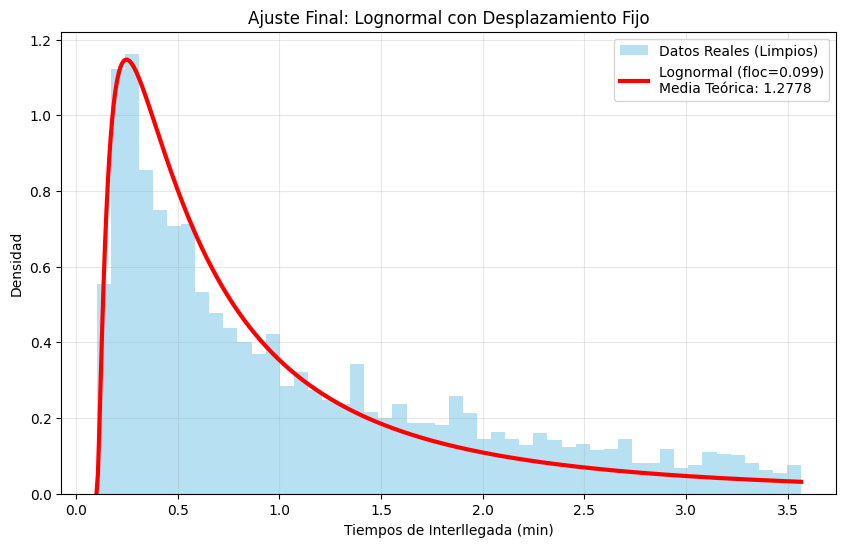

Parámetros finales: Shape=1.1758, Loc=0.099, Scale=0.5905
Diferencia de Medias: 0.1921


In [35]:
from scipy.optimize import curve_fit

# 1. Obtenemos las alturas y centros de las barras del histograma
y_real, x_edges = np.histogram(data, bins=50, density=True)
x_centers = (x_edges[1:] + x_edges[:-1]) / 2

# 2. Definimos la función lognormal para optimizar
def lognorm_func(x, s, loc, scale):
    return stats.lognorm.pdf(x, s, loc, scale)

# 3. Ajustamos mediante mínimos cuadrados
popt, _ = curve_fit(lognorm_func, x_centers, y_real, p0=[0.9, 0.1, 0.6])

print(f"Parámetros optimizados (mínimos cuadrados): {popt}")

from sklearn.metrics import mean_squared_error, r2_score

# Calculamos los valores de la PDF teórica en los mismos puntos que el histograma
pdf_optimizada = stats.lognorm.pdf(x_centers, *popt)

# Métricas
mse = mean_squared_error(y_real, pdf_optimizada)
r2 = r2_score(y_real, pdf_optimizada)

print(f"MSE (Menor es mejor): {mse:.6f}")
print(f"R-squared: {r2:.4f}")

datos_sinteticos = stats.lognorm.rvs(*popt, size=10000)

print(f"Media Real: {data.mean():.4f} vs Media Modelo: {datos_sinteticos.mean():.4f}")
print(f"Std Real: {data.std():.4f} vs Std Modelo: {datos_sinteticos.std():.4f}")

# 1. Realizar el ajuste fijando el límite inferior (floc)
# Usamos los datos originales (limpios)
params_f = stats.lognorm.fit(data, floc=0.099)
s_f, loc_f, scale_f = params_f

# 2. Calcular la media teórica para verificar la precisión
# Formula: exp(mu + sigma^2 / 2) + loc, donde scale = exp(mu)
media_teorica = np.exp(np.log(scale_f) + (s_f**2)/2) + loc_f

# 3. Graficar
plt.figure(figsize=(10, 6))
# Histograma real
plt.hist(data, bins=50, density=True, alpha=0.6, color='skyblue', label='Datos Reales (Limpios)')

# Línea del ajuste Lognormal con floc=0.1
x = np.linspace(data.min(), data.max(), 500)
pdf_f = stats.lognorm.pdf(x, *params_f)
plt.plot(x, pdf_f, 'r-', lw=3, label=f'Lognormal (floc=0.099)\nMedia Teórica: {media_teorica:.4f}')

plt.title('Ajuste Final: Lognormal con Desplazamiento Fijo')
plt.xlabel('Tiempos de Interllegada (min)')
plt.ylabel('Densidad')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print(f"Parámetros finales: Shape={s_f:.4f}, Loc={loc_f}, Scale={scale_f:.4f}")
print(f"Diferencia de Medias: {abs(data.mean() - media_teorica):.4f}")